# From RNN to LSTM to Transformer

---

Creator: Chung-En Johnny Yu

Content updated: 2026-10-29

Hands-on practice this notebook on your Google Colab:
1. [Click here to open this notebook](https://colab.research.google.com/github/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00_rnn_lstm_to_transformer.ipynb)
2. Now, run the code and practice it!

Extends `02_attention.ipynb` by covering the part that comes *before* attention: recurrent networks, why they struggle, and what the Transformer changed.

**Sources** — sections taken from Raschka are tagged; everything else is written for this notebook:

| Tag | Source |
|---|---|
| 📘 **[MLPyTorch Ch15]** | Raschka, Liu & Mirjalili, *Machine Learning with PyTorch and Scikit-Learn* (Packt, 2022), Ch. 15 — [code & figures](https://github.com/rasbt/machine-learning-book/tree/main/ch15) |
| 📗 **[LLMs-from-scratch Ch3]** | Sebastian Raschka, *Build a Large Language Model (From Scratch)* (Manning, 2024), Ch. 3 — [notebook](https://github.com/rasbt/LLMs-from-scratch/blob/main/ch03/01_main-chapter-code/ch03.ipynb) |

Runs in Google Colab on CPU in a few minutes (faster with a GPU runtime). No model weights are downloaded.

| Part | Content |
|---|---|
| 1 | Sequential data and what an RNN is |
| 2 | Computing RNN activations by hand (checked against `nn.RNN`) |
| 3 | Why long-range dependencies are hard: vanishing gradients |
| 4 | The LSTM cell |
| 5 | Project: a character-level LSTM language model |
| 6 | From RNNs to attention to the Transformer |
| 7 | Experiment: RNN vs LSTM vs Transformer on long-range recall |
| 8 | Roadmap and interview-style check questions |

---

In [1]:
import math, os, time, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device)

torch 2.13.0 | device: cpu


## 1. Sequential data and recurrent networks

📘 *[MLPyTorch Ch15] figures*

In sequential data **order matters**: text, speech, sensor streams, DNA. A model has to process the elements in context, not as independent samples. Depending on the task, inputs and outputs can both be sequences:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_02.png?raw=true" width="500px">

*Figure: categories of sequence modeling. Source: MLPyTorch Ch15, Fig. 15.2.*

- **many-to-one**: sentiment of a review; **one-to-many**: image captioning
- **many-to-many (synchronized)**: tagging every frame/word; **many-to-many (delayed)**: translation — and **language modeling** (predict the next token at every step)

A **recurrent neural network** adds a loop: the hidden layer at step $t$ receives the current input *and* its own previous state.

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_03.png?raw=true" width="450px">

*Figure: feedforward network vs. RNN with a recurrent edge. Source: MLPyTorch Ch15, Fig. 15.3.*

"Unfolding" the loop over time shows that the same weights are reused at every step, and that layers can be stacked:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_04.png?raw=true" width="550px">

*Figure: single-layer and multilayer RNNs, folded and unfolded. Source: MLPyTorch Ch15, Fig. 15.4.*

## 2. Computing the activations of an RNN

📘 *[MLPyTorch Ch15] figures and code*

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_05.png?raw=true" width="500px">

*Figure: the three weight matrices $W_{xh}$, $W_{hh}$, $W_{ho}$, shared across time. Source: MLPyTorch Ch15, Fig. 15.5.*

$$
h^{(t)}=\tanh\!\big(W_{xh}x^{(t)}+W_{hh}h^{(t-1)}+b_h\big),\qquad o^{(t)}=\sigma_o\!\big(W_{ho}h^{(t)}+b_o\big).
$$

The two formulations below are the same computation — concatenating $[x^{(t)};h^{(t-1)}]$ and using one stacked matrix $W_h=[W_{xh};W_{hh}]$ is how many libraries implement it:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_06.png?raw=true" width="650px">

*Figure: two equivalent formulations of the hidden-state update. Source: MLPyTorch Ch15, Fig. 15.6.*

The code below (from the book) builds a tiny `nn.RNN` and recomputes its output **by hand**, step by step. Note that the update is **sequential**: step $t$ needs step $t-1$.

In [2]:
# Source: MLPyTorch Ch15, ch15_part1.ipynb
torch.manual_seed(1)

rnn_layer = nn.RNN(input_size=5, hidden_size=2, num_layers=1, batch_first=True)

w_xh = rnn_layer.weight_ih_l0
w_hh = rnn_layer.weight_hh_l0
b_xh = rnn_layer.bias_ih_l0
b_hh = rnn_layer.bias_hh_l0

print('W_xh shape:', w_xh.shape)
print('W_hh shape:', w_hh.shape)
print('b_xh shape:', b_xh.shape)
print('b_hh shape:', b_hh.shape)

W_xh shape: torch.Size([2, 5])
W_hh shape: torch.Size([2, 2])
b_xh shape: torch.Size([2])
b_hh shape: torch.Size([2])


In [3]:
# Source: MLPyTorch Ch15, ch15_part1.ipynb
x_seq = torch.tensor([[1.0]*5, [2.0]*5, [3.0]*5]).float()

## output of the simple RNN:
output, hn = rnn_layer(torch.reshape(x_seq, (1, 3, 5)))

## manually computing the output:
out_man = []
for t in range(3):
    xt = torch.reshape(x_seq[t], (1, 5))
    print(f'Time step {t} =>')
    print('   Input           :', xt.numpy())

    ht = torch.matmul(xt, torch.transpose(w_xh, 0, 1)) + b_xh
    print('   Hidden          :', ht.detach().numpy())

    if t>0:
        prev_h = out_man[t-1]
    else:
        prev_h = torch.zeros((ht.shape))

    ot = ht + torch.matmul(prev_h, torch.transpose(w_hh, 0, 1)) + b_hh
    ot = torch.tanh(ot)
    out_man.append(ot)
    print('   Output (manual) :', ot.detach().numpy())
    print('   RNN output      :', output[:, t].detach().numpy())
    print()

Time step 0 =>
   Input           : [[1. 1. 1. 1. 1.]]
   Hidden          : [[-0.47019297  0.58639044]]
   Output (manual) : [[-0.35198015  0.52525216]]
   RNN output      : [[-0.3519801   0.52525216]]

Time step 1 =>
   Input           : [[2. 2. 2. 2. 2.]]
   Hidden          : [[-0.8888316  1.2364398]]
   Output (manual) : [[-0.68424344  0.76074266]]
   RNN output      : [[-0.68424344  0.76074266]]

Time step 2 =>
   Input           : [[3. 3. 3. 3. 3.]]
   Hidden          : [[-1.3074702  1.8864892]]
   Output (manual) : [[-0.8649416  0.9046636]]
   RNN output      : [[-0.8649416  0.9046636]]



In [4]:
# turn the visual comparison into a test
assert torch.allclose(torch.cat(out_man), output[0], atol=1e-6)
print("manual recurrence == nn.RNN output ✓")

manual recurrence == nn.RNN output ✓


## 3. The challenge of learning long-range interactions

📘 *[MLPyTorch Ch15] figure*

Training an RNN uses **backpropagation through time** (BPTT). The gradient of a loss at step $T$ with respect to an early hidden state is a product of one Jacobian per step:

$$
\frac{\partial h^{(T)}}{\partial h^{(1)}}=\prod_{t=2}^{T}\frac{\partial h^{(t)}}{\partial h^{(t-1)}}
=\prod_{t=2}^{T}\operatorname{diag}\!\big(1-(h^{(t)})^2\big)\,W_{hh}.
$$

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_08.png?raw=true" width="500px">

*Figure: with a recurrent weight below 1 the signal vanishes, above 1 it explodes; only $|w_{hh}|=1$ preserves it. Source: MLPyTorch Ch15, Fig. 15.8.*

The one-dimensional picture generalizes: if the typical singular value of each factor is below 1 the product shrinks **exponentially** in $T$. Gradient clipping fixes explosion, **not** vanishing. Common remedies: gradient clipping, truncated BPTT, and — most effectively — gated cells such as the LSTM.

Let us measure $\lVert\partial h^{(T)}/\partial x^{(1)}\rVert$ for a freshly initialized RNN and LSTM:

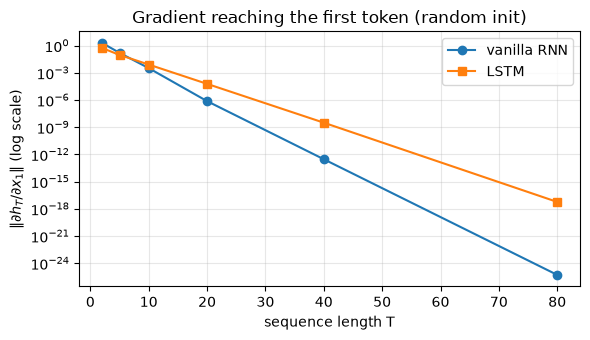

T=  2   RNN 1.93e+00   LSTM 5.34e-01
T=  5   RNN 1.55e-01   LSTM 9.16e-02
T= 10   RNN 3.20e-03   LSTM 7.95e-03
T= 20   RNN 7.32e-07   LSTM 5.90e-05
T= 40   RNN 2.87e-13   LSTM 3.08e-09
T= 80   RNN 5.01e-26   LSTM 5.59e-18


In [5]:
def grad_from_first_input(cell_kind, T, d=64, seed=0):
    torch.manual_seed(seed)
    x = torch.randn(1, T, d, dtype=torch.float64, requires_grad=True)   # float64: avoid underflow
    net = (nn.RNN if cell_kind == "RNN" else nn.LSTM)(d, d, batch_first=True).double()
    out, _ = net(x)
    out[0, -1].sum().backward()
    return x.grad[0, 0].norm().item()

Ts = [2, 5, 10, 20, 40, 80]
g_rnn = [sum(grad_from_first_input("RNN", T, seed=s) for s in range(5)) / 5 for T in Ts]
g_lstm = [sum(grad_from_first_input("LSTM", T, seed=s) for s in range(5)) / 5 for T in Ts]

plt.figure(figsize=(6, 3.5))
plt.semilogy(Ts, g_rnn, "o-", label="vanilla RNN")
plt.semilogy(Ts, g_lstm, "s-", label="LSTM")
plt.xlabel("sequence length T"); plt.ylabel(r"$\|\partial h_T / \partial x_1\|$ (log scale)")
plt.title("Gradient reaching the first token (random init)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
for T, a, b in zip(Ts, g_rnn, g_lstm):
    print(f"T={T:3d}   RNN {a:.2e}   LSTM {b:.2e}")

A straight line on a log axis is the signature of **exponential decay**. A random, untrained LSTM also decays; its advantage is that training can *learn* to keep its forget gate near 1 and open an almost-identity path through time (see Part 7).

## 4. Long short-term memory (LSTM)

📘 *[MLPyTorch Ch15] figure*

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_09.png?raw=true" width="650px">

*Figure: the LSTM cell — forget gate $f$, input gate $i$, candidate $\tilde{C}$, output gate $o$, and the cell state $C$ running along the top. Source: MLPyTorch Ch15, Fig. 15.9.*

$$
\begin{aligned}
f_t &= \sigma(W_{xf}x_t+W_{hf}h_{t-1}+b_f) &&\text{how much old memory to keep}\\
i_t &= \sigma(W_{xi}x_t+W_{hi}h_{t-1}+b_i) &&\text{how much new content to write}\\
\tilde C_t &= \tanh(W_{xc}x_t+W_{hc}h_{t-1}+b_c) &&\text{candidate content}\\
o_t &= \sigma(W_{xo}x_t+W_{ho}h_{t-1}+b_o) &&\text{how much memory to expose}\\
C_t &= f_t\odot C_{t-1} + i_t\odot \tilde C_t, \qquad h_t = o_t\odot\tanh(C_t)
\end{aligned}
$$

The key is the **additive** cell-state update. Along that path $\partial C_t/\partial C_{t-1}\approx\operatorname{diag}(f_t)$: with $f_t\approx1$ the gradient passes almost unchanged — the same idea as the **residual connection** in every Transformer block.

A from-scratch cell, checked against PyTorch:

In [6]:
class LSTMCellScratch(nn.Module):
    def __init__(self, d_in, d_h):
        super().__init__()
        self.x2g = nn.Linear(d_in, 4 * d_h)              # all four gates in one matmul
        self.h2g = nn.Linear(d_h, 4 * d_h)

    def forward(self, x, state):
        h, c = state
        i, f, g, o = (self.x2g(x) + self.h2g(h)).chunk(4, dim=-1)   # PyTorch gate order: i, f, g, o
        i, f, g, o = torch.sigmoid(i), torch.sigmoid(f), torch.tanh(g), torch.sigmoid(o)
        c = f * c + i * g
        h = o * torch.tanh(c)
        return h, c

d_in, d_h = 8, 16
ref = nn.LSTMCell(d_in, d_h)
mine = LSTMCellScratch(d_in, d_h)
with torch.no_grad():
    mine.x2g.weight.copy_(ref.weight_ih); mine.x2g.bias.copy_(ref.bias_ih)
    mine.h2g.weight.copy_(ref.weight_hh); mine.h2g.bias.copy_(ref.bias_hh)
x = torch.randn(4, d_in); h0 = torch.randn(4, d_h); c0 = torch.randn(4, d_h)
h_ref, c_ref = ref(x, (h0, c0))
h_me, c_me = mine(x, (h0, c0))
assert torch.allclose(h_ref, h_me, atol=1e-6) and torch.allclose(c_ref, c_me, atol=1e-6)
print("scratch LSTM cell matches nn.LSTMCell ✓")

scratch LSTM cell matches nn.LSTMCell ✓


## 5. Project: a character-level LSTM language model

📘 *[MLPyTorch Ch15] figures and code (adapted for CPU/Colab)*

This is the same objective a GPT uses — **predict the next token** — with characters as tokens and an LSTM as the model.

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_11.png?raw=true" width="600px">

*Figure: break text into characters; at every position the target is the next character. Source: MLPyTorch Ch15, Fig. 15.11.*

The training text is Jules Verne's *The Mysterious Island* (Project Gutenberg, public domain).

In [7]:
# download helper: local copy -> this repo -> original book repo
fname = "1268-0.txt"
urls = [
    "https://raw.githubusercontent.com/chungenyu6/ai-learning-notebooks/main/02-LLM/live/00-rnn_lstm_to_transformer/data/1268-0.txt",
    "https://raw.githubusercontent.com/rasbt/machine-learning-book/main/ch15/1268-0.txt",
]
local = os.path.join("00-rnn_lstm_to_transformer", "data", fname)
if os.path.exists(local):
    fname = local
elif not os.path.exists(fname):
    for url in urls:
        try:
            urllib.request.urlretrieve(url, fname); break
        except Exception as e:
            print("could not download", url, e)
print("using", fname)

using 00-rnn_lstm_to_transformer/data/1268-0.txt


In [8]:
# Source: MLPyTorch Ch15, ch15_part3.ipynb
## Reading and processing text
with open(fname, 'r', encoding="utf8") as fp:
    text=fp.read()

start_indx = text.find('THE MYSTERIOUS ISLAND')
end_indx = text.find('End of the Project Gutenberg')

text = text[start_indx:end_indx]
char_set = set(text)
print('Total Length:', len(text))
print('Unique Characters:', len(char_set))

Total Length: 1112350
Unique Characters: 80


Each character is mapped to an integer id — the simplest possible **tokenizer** (`01_tokenization_clm_mlm` replaces it with subword BPE):

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_12.png?raw=true" width="500px">

*Figure: dictionaries mapping characters to integers and back. Source: MLPyTorch Ch15, Fig. 15.12.*

In [9]:
# Source: MLPyTorch Ch15, ch15_part3.ipynb
chars_sorted = sorted(char_set)
char2int = {ch:i for i,ch in enumerate(chars_sorted)}
char_array = np.array(chars_sorted)

text_encoded = np.array(
    [char2int[ch] for ch in text],
    dtype=np.int32)

print('Text encoded shape: ', text_encoded.shape)

print(text[:15], '     == Encoding ==> ', text_encoded[:15])
print(text_encoded[15:21], ' == Reverse  ==> ', ''.join(char_array[text_encoded[15:21]]))

Text encoded shape:  (1112350,)
THE MYSTERIOUS       == Encoding ==>  [44 32 29  1 37 48 43 44 29 42 33 39 45 43  1]
[33 43 36 25 38 28]  == Reverse  ==>  ISLAND


Training examples are fixed-length chunks. The book contrasts two ways to build targets — predicting only the character *after* the chunk (left), or the **input shifted by one** at every position (right). The shifted version gives a training signal at every step and is exactly how GPT-style models are trained:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_13.png?raw=true" width="420px"> <img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/15_14.png?raw=true" width="420px">

*Figures: one target per chunk vs. input/target shifted by one. Source: MLPyTorch Ch15, Figs. 15.13–15.14.*

In [10]:
# Source: MLPyTorch Ch15, ch15_part3.ipynb
seq_length = 40
chunk_size = seq_length + 1

text_chunks = [text_encoded[i:i+chunk_size]
               for i in range(len(text_encoded)-chunk_size+1)]

from torch.utils.data import Dataset

class TextDataset(Dataset):
    def __init__(self, text_chunks):
        self.text_chunks = text_chunks

    def __len__(self):
        return len(self.text_chunks)

    def __getitem__(self, idx):
        text_chunk = self.text_chunks[idx]
        return text_chunk[:-1].long(), text_chunk[1:].long()

seq_dataset = TextDataset(torch.tensor(np.array(text_chunks)))

for i, (seq, target) in enumerate(seq_dataset):
    print(' Input (x):', repr(''.join(char_array[seq])))
    print('Target (y):', repr(''.join(char_array[target])))
    print()
    if i == 1:
        break

 Input (x): 'THE MYSTERIOUS ISLAND ***\n\n\n\n\nProduced b'
Target (y): 'HE MYSTERIOUS ISLAND ***\n\n\n\n\nProduced by'

 Input (x): 'HE MYSTERIOUS ISLAND ***\n\n\n\n\nProduced by'
Target (y): 'E MYSTERIOUS ISLAND ***\n\n\n\n\nProduced by '



In [11]:
# Source: MLPyTorch Ch15, ch15_part3.ipynb
from torch.utils.data import DataLoader

batch_size = 64

torch.manual_seed(1)
seq_dl = DataLoader(seq_dataset, batch_size=batch_size, shuffle=True, drop_last=True)

class RNN(nn.Module):
    def __init__(self, vocab_size, embed_dim, rnn_hidden_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.rnn_hidden_size = rnn_hidden_size
        self.rnn = nn.LSTM(embed_dim, rnn_hidden_size,
                           batch_first=True)
        self.fc = nn.Linear(rnn_hidden_size, vocab_size)

    def forward(self, x, hidden, cell):
        out = self.embedding(x).unsqueeze(1)
        out, (hidden, cell) = self.rnn(out, (hidden, cell))
        out = self.fc(out).reshape(out.size(0), -1)
        return out, hidden, cell

    def init_hidden(self, batch_size):
        hidden = torch.zeros(1, batch_size, self.rnn_hidden_size)
        cell = torch.zeros(1, batch_size, self.rnn_hidden_size)
        return hidden.to(device), cell.to(device)

vocab_size = len(char_array)
embed_dim = 256
rnn_hidden_size = 512

torch.manual_seed(1)
model = RNN(vocab_size, embed_dim, rnn_hidden_size)
model = model.to(device)
model

RNN(
  (embedding): Embedding(80, 256)
  (rnn): LSTM(256, 512, batch_first=True)
  (fc): Linear(in_features=512, out_features=80, bias=True)
)

The training loop feeds **one character per step** and carries `(hidden, cell)` forward — the sequential bottleneck in action. The book trains for 10,000 iterations on a GPU; on a CPU runtime we use 800 (≈2–4 minutes), which is enough to learn words and punctuation. Switch Colab to a GPU runtime to run the full schedule.

In [12]:
# Source: MLPyTorch Ch15, ch15_part3.ipynb; iteration count adapted for CPU
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005)

num_epochs = 10000 if device.type == "cuda" else 800
print_every = 500 if device.type == "cuda" else 100

torch.manual_seed(1)
t0 = time.time()
for epoch in range(num_epochs):
    hidden, cell = model.init_hidden(batch_size)
    seq_batch, target_batch = next(iter(seq_dl))
    seq_batch = seq_batch.to(device)
    target_batch = target_batch.to(device)
    optimizer.zero_grad()
    loss = 0
    for c in range(seq_length):
        pred, hidden, cell = model(seq_batch[:, c], hidden, cell)
        loss += loss_fn(pred, target_batch[:, c])
    loss.backward()
    optimizer.step()
    loss = loss.item()/seq_length
    if epoch % print_every == 0 or epoch == num_epochs - 1:
        print(f'Epoch {epoch} loss: {loss:.4f}')
print(f"({time.time() - t0:.0f}s)")

Epoch 0 loss: 4.3722


Epoch 100 loss: 1.7092


Epoch 200 loss: 1.5436


Epoch 300 loss: 1.4602


Epoch 400 loss: 1.4387


Epoch 500 loss: 1.3920


Epoch 600 loss: 1.3356


Epoch 700 loss: 1.3491


Epoch 799 loss: 1.3046
(152s)


### Generating text, and the temperature knob

Generation is autoregressive: sample a character from the predicted distribution, feed it back, repeat. The book scales the logits by a factor $\alpha$ before sampling — $\alpha>1$ sharpens the distribution (more predictable), $\alpha<1$ flattens it (more random). This is the same knob LLM APIs expose as **temperature** $T = 1/\alpha$.

In [13]:
# Source: MLPyTorch Ch15, ch15_part3.ipynb
from torch.distributions.categorical import Categorical

logits = torch.tensor([[1.0, 1.0, 3.0]])

print('Probabilities before scaling:        ', nn.functional.softmax(logits, dim=1).numpy()[0])

print('Probabilities after scaling with 0.5:', nn.functional.softmax(0.5*logits, dim=1).numpy()[0])

print('Probabilities after scaling with 0.1:', nn.functional.softmax(0.1*logits, dim=1).numpy()[0])

Probabilities before scaling:         [0.10650698 0.10650698 0.78698605]
Probabilities after scaling with 0.5: [0.21194156 0.21194156 0.57611686]
Probabilities after scaling with 0.1: [0.3104238  0.3104238  0.37915248]


In [14]:
# Source: MLPyTorch Ch15, ch15_part3.ipynb; device handling adapted
def sample(model, starting_str,
           len_generated_text=500,
           scale_factor=1.0):

    encoded_input = torch.tensor([char2int[s] for s in starting_str])
    encoded_input = torch.reshape(encoded_input, (1, -1))

    generated_str = starting_str

    model.eval()
    hidden, cell = model.init_hidden(1)
    hidden = hidden.to('cpu')
    cell = cell.to('cpu')
    for c in range(len(starting_str)-1):
        _, hidden, cell = model(encoded_input[:, c].view(1), hidden, cell)

    last_char = encoded_input[:, -1]
    for i in range(len_generated_text):
        logits, hidden, cell = model(last_char.view(1), hidden, cell)
        logits = torch.squeeze(logits, 0)
        scaled_logits = logits * scale_factor
        m = Categorical(logits=scaled_logits)
        last_char = m.sample()
        generated_str += str(char_array[last_char])

    return generated_str

model.to('cpu')
device = torch.device('cpu')   # sampling runs on CPU, as in the book
for scale in (2.0, 1.0, 0.5):
    torch.manual_seed(1)
    print(f"--- scale_factor={scale} ---")
    print(sample(model, starting_str='The island', len_generated_text=250, scale_factor=scale))
    print()

--- scale_factor=2.0 ---
The island would be the reporter was the sea, and the wood of the corral, and the sailor, “you under the strange for the sailor, “that it was nothing of the distance of the colonists was evident the wire the moment as if there was the mouth of the carry of the

--- scale_factor=1.0 ---


The island would dimight enormous to be from the reporter, “and, for which the halso howh, was undoed an hour at fifty miles, whont nor their still be only extremity of the Chimneys, was evidencict-masion
touce to the island.

“They were
there was carry build 

--- scale_factor=0.5 ---


The island foxmess, 16 jTe
me alwDested from?

Neverblank, engs,)-cafward. LI. QKpSLI7” hareable
doera, my debainffel.
LixIshWvede.

“My trave quarting’sly.”

Tbodsyd*cadlud, Cyruate Wasoen, Picirtyins
intle, elkilors instrucfet lying!0Ze1se, Nemo caOyals.

Bu



**What to notice.** Even this small LSTM learns spelling, spacing and punctuation. It loses the thread across sentences: everything the model knows about the past must squeeze through the fixed-size `(hidden, cell)` vectors, one step at a time.

## 6. From RNNs to attention to the Transformer

📗 *[LLMs-from-scratch Ch3] text (§3.1–3.2) and figures*

**The problem with modeling long sequences.** Translating word by word does not work because grammatical structure differs between languages:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/ch03_03.webp?raw=true" width="400px">

*Figure: word-by-word translation fails. Source: Raschka, LLMs-from-scratch Ch3 (original image `ch03_compressed/03.webp`).*

Before Transformers, **encoder–decoder RNNs** were the standard for translation: the encoder reads the source sentence and compresses it into a hidden state; the decoder generates the translation from that state.

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/ch03_04.webp?raw=true" width="500px">

*Figure: encoder–decoder RNN; the whole input must pass through the final hidden state. Source: Raschka, LLMs-from-scratch Ch3 (original image `ch03_compressed/04.webp`).*

Two problems follow: a **bottleneck** (one fixed vector for an arbitrarily long sentence) and **distance** (word 1 must survive every recurrent step).

**Capturing data dependencies with attention.** With an attention mechanism (Bahdanau et al., 2015) the decoder can selectively access *all* encoder states, weighting some input tokens more than others for each output token:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/ch03_05.webp?raw=true" width="500px">

*Figure: attention lets the decoder look at all input tokens. Source: Raschka, LLMs-from-scratch Ch3 (original image `ch03_compressed/05.webp`).*

**Self-attention** in Transformers (Vaswani et al., 2017) lets each position in a sequence attend to every other (allowed) position *in the same sequence* — no recurrence at all:

<img src="https://github.com/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/00-rnn_lstm_to_transformer/img/ch03_06.webp?raw=true" width="300px">

*Figure: self-attention within one sequence. Source: Raschka, LLMs-from-scratch Ch3 (original image `ch03_compressed/06.webp`).*

$$
\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\!\Big(\frac{QK^\top}{\sqrt{d_k}} + M\Big)V,
$$

where $Q,K,V$ are projections of the same sequence and $M$ is the causal mask ($-\infty$ above the diagonal). The main notebook `02_attention.ipynb` and `02_self_and_cross_attention` derive every symbol; here is just the consequence:

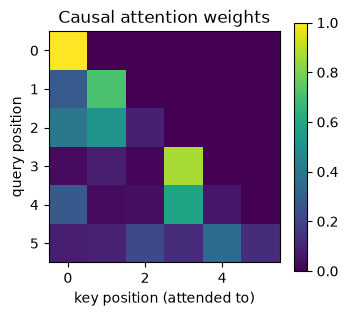

rows sum to 1: True


In [15]:
def causal_self_attention(x, Wq, Wk, Wv):
    """Single-head causal self-attention. x: (B, T, d)."""
    q, k, v = x @ Wq, x @ Wk, x @ Wv
    T = x.shape[1]
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])     # (B, T, T): every pair at once
    mask = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)
    scores = scores.masked_fill(mask, float("-inf"))
    weights = F.softmax(scores, dim=-1)
    return weights @ v, weights

torch.manual_seed(0)
d = 16
x = torch.randn(1, 6, d)
Wq, Wk, Wv = (torch.randn(d, d) / math.sqrt(d) for _ in range(3))
_, w = causal_self_attention(x, Wq, Wk, Wv)
plt.figure(figsize=(3.6, 3.2))
plt.imshow(w[0].detach(), cmap="viridis"); plt.colorbar()
plt.xlabel("key position (attended to)"); plt.ylabel("query position")
plt.title("Causal attention weights"); plt.tight_layout(); plt.show()
print("rows sum to 1:", torch.allclose(w.sum(-1), torch.ones(1, 6)))

Row $t$ shows how token $t$ mixes information from tokens $1..t$; the upper triangle is exactly zero. There is **no loop over time**: token 6 reaches token 1 in one step.

| | RNN / LSTM | Self-attention |
|---|---|---|
| Sequential steps to process $T$ tokens (training) | $O(T)$ — cannot parallelize over time | $O(1)$ — one big matrix multiply |
| Path length between tokens $i$ and $j$ | $O(\lvert i-j\rvert)$ | $O(1)$ |
| Compute per layer | $O(T d^2)$ | $O(T^2 d + T d^2)$ |
| Memory of the past during generation | fixed-size $h_t$ (cheap, lossy) | all past keys/values (exact, grows with $T$ → **KV cache**, see `03_gqa_kv_cache`) |
| Knows word order by itself? | yes (order of the loop) | **no** — needs positional information (learned / sinusoidal / RoPE) |

## 7. Experiment: who can remember the first token?

**Task.** Each sequence is `[k, n, n, ..., n]`: a *key* token followed by $L$ random *noise* tokens. At the last position the model must output the key — a pure long-range dependency. Three small models train for 600 steps each; chance is $1/8$. Models are not parameter-matched: the RNN–LSTM gap and the effect of $L$ are the point, not a benchmark.

L=  5  RNN 100%  LSTM 100%  Transformer 100%


L= 20  RNN 11%  LSTM 100%  Transformer 100%


L= 50  RNN 12%  LSTM 38%  Transformer 100%


L=100  RNN 13%  LSTM 12%  Transformer 100%


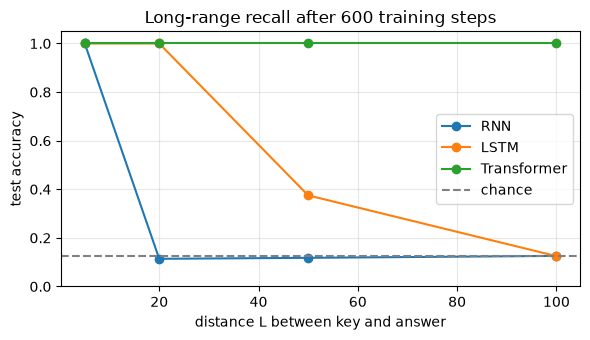

In [16]:
N_KEYS, N_NOISE = 8, 8
VOCAB = N_KEYS + N_NOISE

def recall_batch(L, B=64):
    keys = torch.randint(0, N_KEYS, (B,))
    noise = torch.randint(N_KEYS, VOCAB, (B, L))
    return torch.cat([keys[:, None], noise], dim=1), keys

class RecurrentClassifier(nn.Module):
    def __init__(self, kind, d=64):
        super().__init__()
        self.embed = nn.Embedding(VOCAB, d)
        self.rnn = (nn.RNN if kind == "RNN" else nn.LSTM)(d, d, batch_first=True)
        self.head = nn.Linear(d, N_KEYS)
        if kind == "LSTM":                                 # standard trick: forget-gate bias = 1,
            for name, p in self.rnn.named_parameters():   # so the cell starts by *remembering*
                if "bias" in name:
                    p.data[d:2 * d].fill_(1.0)             # gate order i, f, g, o -> slice 2 is f
    def forward(self, x):
        out, _ = self.rnn(self.embed(x))
        return self.head(out[:, -1])

class TinyTransformer(nn.Module):
    """One pre-norm Transformer block with learned positions and a causal mask."""
    def __init__(self, d=64, n_heads=4, max_len=256):
        super().__init__()
        self.embed = nn.Embedding(VOCAB, d)
        self.pos = nn.Embedding(max_len, d)
        layer = nn.TransformerEncoderLayer(d, n_heads, dim_feedforward=4 * d, dropout=0.0,
                                           batch_first=True, norm_first=True)
        self.block = nn.TransformerEncoder(layer, num_layers=1, enable_nested_tensor=False)
        self.head = nn.Linear(d, N_KEYS)
    def forward(self, x):
        T = x.shape[1]
        h = self.embed(x) + self.pos(torch.arange(T))
        mask = nn.Transformer.generate_square_subsequent_mask(T)
        return self.head(self.block(h, mask=mask, is_causal=True)[:, -1])

def train_and_eval(make_model, L, steps=600, seed=0):
    torch.manual_seed(seed)
    model = make_model()
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    for _ in range(steps):
        x, y = recall_batch(L)
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    with torch.no_grad():
        x, y = recall_batch(L, B=1000)
        return (model(x).argmax(-1) == y).float().mean().item()

models = {"RNN": lambda: RecurrentClassifier("RNN"),
          "LSTM": lambda: RecurrentClassifier("LSTM"),
          "Transformer": lambda: TinyTransformer()}
Ls = [5, 20, 50, 100]
results = {name: [] for name in models}
for L in Ls:
    for name, make in models.items():
        results[name].append(train_and_eval(make, L))
    print(f"L={L:3d}  " + "  ".join(f"{n} {results[n][-1]:.0%}" for n in models))

plt.figure(figsize=(6, 3.5))
for name, accs in results.items():
    plt.plot(Ls, accs, "o-", label=name)
plt.axhline(1 / N_KEYS, color="gray", ls="--", label="chance")
plt.xlabel("distance L between key and answer"); plt.ylabel("test accuracy")
plt.title("Long-range recall after 600 training steps")
plt.ylim(0, 1.05); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

- The **vanilla RNN** solves short distances and collapses toward chance as $L$ grows.
- The **LSTM** holds on much longer thanks to the gated cell state, but it also degrades as $L$ grows — gating slows the decay, it does not remove it. (Without the forget-bias trick it fails at $L=20$ too: try setting the fill value to 0.)
- The **Transformer** reaches the key in one attention hop, so distance barely matters here. It pays with $O(T^2)$ attention and needs explicit position information.

## 8. Where this leads, and check yourself

```
token ids ─► embedding (+ position) ─► [ decoder block × N ] ─► logits ─► next-token loss
                                        │ masked self-attention │
                                        │ + MLP, residual, norm │
```

| Piece of the diagram | Main notebook | Extended material |
|---|---|---|
| token ids, embedding | `01_tokenization` | `01_tokenization_clm_mlm` |
| masked self-attention | `02_attention` | `02_self_and_cross_attention`, `03_gqa_kv_cache` |
| position information | `03_architecture_gpt` | `04_positional_encoding_rope` |
| decoder block × N | `03_architecture_gpt` | `05_gpt_vs_llama_vs_moe` |
| next-token loss, training loop | `04_pretraining` | — |
| fine-tuning | `05_finetuning_classification`, `06_finetuning_instructions` | `06_lora_peft` |

Try answering out loud in 60–90 seconds before opening each answer.

<details><summary><b>Q1. Why do vanilla RNNs struggle with long-range dependencies? Does gradient clipping fix it?</b></summary>

BPTT multiplies one Jacobian $\operatorname{diag}(1-h_t^2)W_{hh}$ per step, so the gradient from step $T$ to step 1 scales roughly like $\lVert W_{hh}\rVert^{T}$: it vanishes or explodes exponentially. Clipping caps exploding gradients but does nothing for vanishing ones. Fixes: gated cells (LSTM/GRU), careful init (orthogonal $W_{hh}$), truncated BPTT for cost, or attention, which gives a direct path.
</details>

<details><summary><b>Q2. What does each LSTM gate do, and why does the cell state help gradients?</b></summary>

Forget gate: how much of $C_{t-1}$ to keep; input gate: how much of the candidate to write; output gate: how much of $\tanh(C_t)$ to expose as $h_t$. Because $C_t=f_t\odot C_{t-1}+i_t\odot\tilde C_t$ is additive, $\partial C_t/\partial C_{t-1}\approx\operatorname{diag}(f_t)$; with $f_t\approx1$ the gradient flows almost unchanged — the same principle as residual connections. Initializing the forget-gate bias to 1 is a standard trick.
</details>

<details><summary><b>Q3. Why are Transformers faster to train than RNNs, but more expensive for long sequences?</b></summary>

With teacher forcing all positions are known, so self-attention computes every position in one batched matmul — no time loop, full GPU parallelism. The score matrix is $T\times T$, so compute and naive memory are $O(T^2)$ per layer versus $O(T)$ for an RNN. At generation time a Transformer keeps keys/values for all past tokens (the KV cache), while an RNN keeps a fixed-size state.
</details>

<details><summary><b>Q4. Self-attention is permutation-equivariant. What does that mean and how is it fixed?</b></summary>

Without position information, shuffling the input tokens just shuffles the outputs — attention sees a set, not a sequence. Fix: learned absolute embeddings (GPT-2), sinusoidal embeddings (original Transformer), or rotating Q and K by position (RoPE; Llama and most modern LLMs).
</details>

<details><summary><b>Q5. Training vs generation for a language model — what differs? What does temperature do?</b></summary>

Training: the input is the true sequence, targets are the same sequence shifted by one, loss averaged over all positions (teacher forcing). Generation: autoregressive — predict, sample, append, repeat; each step depends on previously *generated* tokens (exposure bias). Temperature divides the logits before softmax: low temperature → sharper, more deterministic; high → flatter, more diverse. The char-LSTM's `scale_factor` is 1/temperature.
</details>

## References

- Raschka, Liu & Mirjalili (2022), *Machine Learning with PyTorch and Scikit-Learn*, Ch. 15 — [rasbt/machine-learning-book](https://github.com/rasbt/machine-learning-book/tree/main/ch15).
- Raschka (2024), *Build a Large Language Model (From Scratch)*, Ch. 3 — [rasbt/LLMs-from-scratch](https://github.com/rasbt/LLMs-from-scratch/tree/main/ch03).
- Hochreiter & Schmidhuber (1997), *Long Short-Term Memory*.
- Bahdanau, Cho & Bengio (2015), *Neural Machine Translation by Jointly Learning to Align and Translate*, [arXiv:1409.0473](https://arxiv.org/abs/1409.0473).
- Vaswani et al. (2017), *Attention Is All You Need*, [arXiv:1706.03762](https://arxiv.org/abs/1706.03762).